# Autoencoders for long-term time-series forecasting
### A hands-on reading of *Are Transformers Effective for Time Series Forecasting?* (Zeng, Chen, Zhang & Xu, AAAI 2023)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/D2718281828nis/ML-Transformers/blob/main/notebooks/autoencoders/02_autoencoders_for_time_series_forecasting.ipynb)
· Interactive version: **[Autoencoder Explainer, part 4–6](https://d2718281828nis.github.io/ML-Transformers/autoencoders/#s-paper)**
· Previous notebook: [01 · Autoencoders and VAEs from scratch](01_autoencoders_and_vae.ipynb)

The paper ([arXiv:2205.13504](https://arxiv.org/abs/2205.13504)) showed that a **single linear layer** beats the
Transformer-based forecasters of its time (Informer, Autoformer, FEDformer, Pyraformer, LogTrans) on the standard long-term
forecasting benchmarks, often by 20–50%. This notebook asks a follow-up question:

> **If one linear map is enough, what is an autoencoder good for in forecasting, and how should it be built so that it respects the
> paper's lessons?**

The answer we arrive at: the *useful* part of the paper's linear map is **low-rank**. It factors into an *encoder* that compresses
the past into a few numbers and a *decoder* that expands them into the future. Building the forecaster that way gives the same
accuracy with 5–14× fewer parameters and an interpretable latent space. The variational version adds prediction intervals that
are sharper than the usual residual-based ones.

**Plan**

1. The paper in one page
2. Data: ETTh1 and the standard protocol
3. Reproducing the baselines (Repeat, Linear, NLinear, DLinear), and DMS vs IMS
4. From LTSF-Linear to an autoencoder: the low-rank view
5. Other ways to use an autoencoder: two-stage, multi-task, nonlinear
6. Benchmark on all four horizons, next to the paper's numbers
7. The paper's diagnostics, applied to the autoencoder: look-back window, input shuffling, efficiency
8. A conditional VAE for probabilistic forecasts
9. Takeaways and related work

Runtime: about 5–8 minutes on a laptop CPU. The ETTh1 dataset (2.5 MB) is downloaded on first run. Peak memory is about 1 GB.

## 1. The paper in one page

**Task.** Given the last $L$ values of a multivariate series with $C$ variables, predict the next $T$ values of every variable:

$$ \mathcal{X} = \{X^t_1, \dots, X^t_C\}_{t=1}^{L} \;\longmapsto\; \hat{\mathcal{X}} = \{\hat X^t_1, \dots, \hat X^t_C\}_{t=L+1}^{L+T}. $$

"Long-term" means $T \gg 1$: 96 to 720 hours ahead on hourly data.

**IMS vs DMS.** An *iterated multi-step* (IMS) forecaster predicts one step, appends it to the input, and repeats, so its errors
compound. A *direct multi-step* (DMS) forecaster outputs all $T$ values at once. The paper notes that the Transformer papers
compared themselves with IMS baselines while using DMS decoders themselves. It argues that much of their reported gain came
from DMS, not from attention.

**The argument against attention.** Self-attention is *permutation-invariant*: shuffle the input tokens and the outputs are shuffled
the same way. Order only enters through positional or timestamp embeddings. Words carry meaning on their own. A single number in a
time series carries little, and the information is mostly in the **order**, so some temporal information is lost.

**LTSF-Linear.** Three "embarrassingly simple" DMS models, each applied to every variable separately with **shared weights**
(channel independence):

| model | forecast for one variable $x \in \mathbb{R}^L$ | why |
|---|---|---|
| **Linear** | $\hat y = W x + b,\quad W \in \mathbb{R}^{T\times L}$ | one weighted sum of the past per future step |
| **NLinear** | $\hat y = W (x - x_L) + b + x_L$ | subtract the last value, add it back: robust to level shifts between train and test |
| **DLinear** | $\hat y = W_s (x - \mathrm{MA}_{25}(x)) + W_t\, \mathrm{MA}_{25}(x)$ | separate linear maps for trend (moving average) and remainder |

**Main findings** (all numbers from the paper):

* On nine benchmarks (ETTh1/h2/m1/m2, Electricity, Exchange, Traffic, Weather, ILI), the best LTSF-Linear variant beats the best
  Transformer **in every setting** of the multivariate benchmark (Table 2). On ETTh1 at $T=96$ the gap is small (0.374 vs FEDformer's 0.376);
  on Exchange-Rate it is 45%.
* Transformers **do not benefit from longer look-back windows**; LTSF-Linear does (Fig. 4).
* Turning Informer step by step into a linear model **improves** it: ETTh1, $T=96$: 0.865 → 0.613 → 0.454 → 0.400 (Table 4).
* **Shuffling** the input window barely changes Informer's error (+2% on ETTh1) but raises Linear's by 81% (Table 5). Linear actually
  uses the order; Informer mostly does not.
* DLinear needs 0.04 G MACs and 140 K parameters, against 4 G MACs and 14–21 M parameters for the Transformers (Table 8, $L=96$, $T=720$).

**Lessons to carry into any new model**, including ours:

| # | lesson | how we apply it |
|---|---|---|
| P1 | forecast all steps at once (DMS) | the decoder outputs $T$ values in one shot |
| P2 | channel independence: one shared model per variable | every window of every variable is one training sample |
| P3 | handle distribution shift | NLinear's last-value normalization |
| P4 | trend/remainder decomposition can help | optional DLinear-style two-branch variant |
| P5 | stay order-aware and small | linear encoder over the whole window; few parameters |
| P6 | always compare with Repeat and Linear | both are in every table below |

In [1]:
import os
import math
import time
import pathlib
import urllib.error
import urllib.request

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from cycler import cycler

torch.manual_seed(0)
np.random.seed(0)
torch.set_num_threads(min(8, os.cpu_count() or 1))

INK, INK2, MUTED, HAIR = "#1c1b19", "#45433e", "#76736b", "#e3e0d8"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": "#c9c5ba", "axes.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": HAIR, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.8, "legend.frameon": False, "axes.prop_cycle": cycler(color=[BLUE, ORANGE, AQUA]),
})
pd.set_option("display.precision", 3)

## 2. Data: ETTh1 and the standard protocol

**ETTh1** (*Electricity Transformer Temperature*, hourly; Zhou et al., 2021) has 7 variables from a power transformer between July 2016
and July 2018: six load measurements (high/middle/low "useful" and "useless" load) and the oil temperature `OT`. We follow the protocol used
by Informer, Autoformer, FEDformer and the paper:

* train / validation / test = the first 12 / next 4 / next 4 months (8,640 / 2,880 / 2,880 hours);
* every variable is z-scored with the **training** mean and standard deviation;
* look-back $L = 336$ hours for the linear models (the paper's default), horizons $T \in \{96, 192, 336, 720\}$;
* MSE and MAE are averaged over all test windows, all horizon steps and all 7 variables, in z-scored units.

In [2]:
def download(url, path):
    try:
        urllib.request.urlretrieve(url, path)
    except urllib.error.URLError:
        # python.org builds on macOS ship without CA certificates; certifi provides them.
        import ssl
        import certifi
        ctx = ssl.create_default_context(cafile=certifi.where())
        with urllib.request.urlopen(url, context=ctx) as r:
            path.write_bytes(r.read())


DATA = pathlib.Path("data")
DATA.mkdir(exist_ok=True)
CSV = DATA / "ETTh1.csv"
if not CSV.exists():
    download("https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv", CSV)

df = pd.read_csv(CSV, parse_dates=["date"])
VARS = list(df.columns[1:])
raw = df[VARS].to_numpy(np.float32)
MONTH = 30 * 24
BORDERS = {"train": (0, 12 * MONTH), "val": (12 * MONTH, 16 * MONTH), "test": (16 * MONTH, 20 * MONTH)}
mean, std = raw[:12 * MONTH].mean(0), raw[:12 * MONTH].std(0)
series = torch.from_numpy((raw - mean) / std)          # (time, 7), z-scored with training statistics
print(df.shape, VARS)
print(f"time range {df.date.iloc[0]} → {df.date.iloc[20 * MONTH - 1]} (the protocol uses the first {20 * MONTH} hours)")

(17420, 8) ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
time range 2016-07-01 00:00:00 → 2018-02-20 23:00:00 (the protocol uses the first 14400 hours)


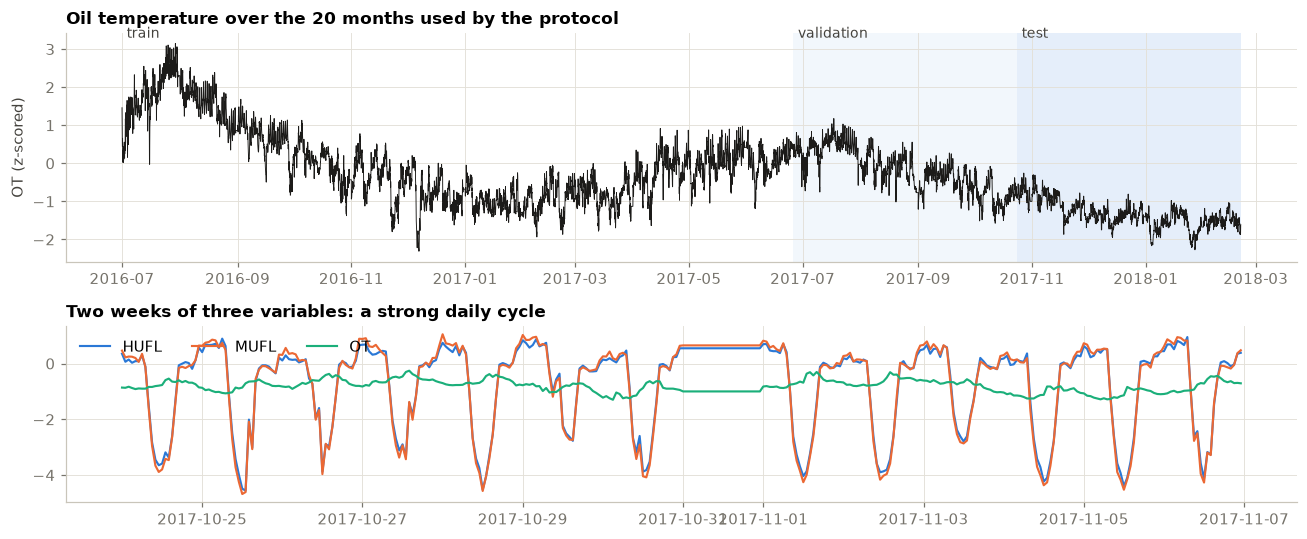

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), gridspec_kw={"height_ratios": [1.3, 1]})
ax = axes[0]
ax.plot(df.date[:20 * MONTH], series[:20 * MONTH, -1], color=INK, lw=0.6)
for name, (a, b), shade in [("train", BORDERS["train"], 0.0), ("validation", BORDERS["val"], 0.06), ("test", BORDERS["test"], 0.12)]:
    ax.axvspan(df.date[a], df.date[b - 1], color=BLUE, alpha=shade, lw=0)
    ax.text(df.date[a + 60], 3.3, name, fontsize=9, color=INK2)
ax.set_ylabel("OT (z-scored)")
ax.set_title("Oil temperature over the 20 months used by the protocol", loc="left")
ax = axes[1]
week = slice(16 * MONTH, 16 * MONTH + 14 * 24)
for v, c in zip(["HUFL", "MUFL", "OT"], [BLUE, ORANGE, AQUA]):
    ax.plot(df.date[week], series[week, VARS.index(v)], color=c, lw=1.4, label=v)
ax.set_title("Two weeks of three variables: a strong daily cycle", loc="left")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

Notice how the oil temperature's level drifts: the test period (autumn 2017) sits lower than the training year. This **distribution
shift** is what NLinear's last-value normalization targets (paper, Appendix D.1 and Fig. 5):

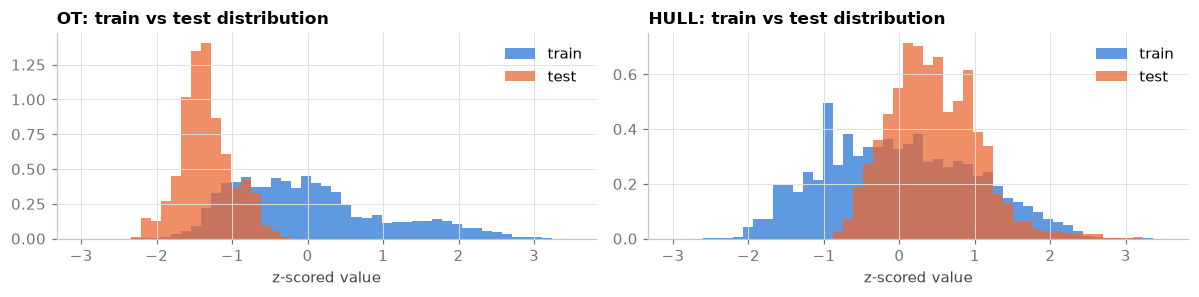

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, v in zip(axes, ["OT", "HULL"]):
    j = VARS.index(v)
    bins = np.linspace(-3, 3.5, 50)
    ax.hist(series[slice(*BORDERS["train"]), j], bins=bins, density=True, color=BLUE, alpha=0.75, label="train")
    ax.hist(series[slice(*BORDERS["test"]), j], bins=bins, density=True, color=ORANGE, alpha=0.75, label="test")
    ax.set_title(f"{v}: train vs test distribution", loc="left")
    ax.set_xlabel("z-scored value")
    ax.legend()
plt.tight_layout()
plt.show()

**Windows.** A sample is $L$ consecutive hours of *one* variable as input and the next $T$ hours of the same variable as target
(channel independence). Validation and test windows start $L$ hours before their split, so that their *targets* lie entirely inside
the split.

In [5]:
def windows(L, T, split):
    """All (input, target) windows of a split, flattened over variables: shapes (n * 7, L) and (n * 7, T)."""
    a, b = BORDERS[split]
    a = a if split == "train" else a - L
    seg = series[a:b]                                              # (time, 7)
    n = len(seg) - L - T + 1
    idx = torch.arange(n)[:, None] + torch.arange(L + T)[None]
    w = seg[idx].permute(0, 2, 1).reshape(-1, L + T)               # window-major, then variable
    return w[:, :L].contiguous(), w[:, L:].contiguous()


x_tr, y_tr = windows(336, 96, "train")
x_te, y_te = windows(336, 96, "test")
print(f"L=336, T=96: {len(x_tr):,} training samples ({len(x_tr) // 7:,} windows × 7 variables), {len(x_te):,} test samples")

L=336, T=96: 57,463 training samples (8,209 windows × 7 variables), 19,495 test samples


## 3. Reproducing the baselines

All models below follow the official LTSF-Linear training recipe: MSE loss, Adam with learning rate 0.005, batch size 32, at most
10 epochs, the learning rate halved after every epoch, and early stopping on validation MSE (patience 3). One difference: we score
**all** test windows, where the official loader drops the last incomplete batch.

In [6]:
def moving_avg(x, k=25):
    """Moving average with edge replication, as in Autoformer/DLinear."""
    pad = (k - 1) // 2
    xp = torch.cat([x[:, :1].expand(-1, pad), x, x[:, -1:].expand(-1, pad)], dim=1)
    return F.avg_pool1d(xp[:, None], k, stride=1)[:, 0]


class Repeat(nn.Module):
    """Repeat the last observed value T times."""

    def __init__(self, L, T):
        super().__init__()
        self.T = T

    def forward(self, x):
        return x[:, -1:].expand(-1, self.T)


class Linear(nn.Module):
    """Linear (norm=False) and NLinear (norm=True)."""

    def __init__(self, L, T, norm=False):
        super().__init__()
        self.lin, self.norm = nn.Linear(L, T), norm

    def forward(self, x):
        last = x[:, -1:] if self.norm else 0
        return self.lin(x - last) + last


class DLinear(nn.Module):
    def __init__(self, L, T):
        super().__init__()
        self.seasonal, self.trend = nn.Linear(L, T), nn.Linear(L, T)

    def forward(self, x):
        trend = moving_avg(x)
        return self.seasonal(x - trend) + self.trend(trend)


def forecast_loss(model, x, y):
    return F.mse_loss(model(x), y)


def fit(model, L, T, loss_fn=forecast_loss, epochs=10, lr=0.005, bs=32, seed=0):
    """Official LTSF-Linear recipe. Returns the model with its best validation weights."""
    if not any(p.requires_grad for p in model.parameters()):
        return model
    x, y = windows(L, T, "train")
    xv, yv = windows(L, T, "val")
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    g = torch.Generator().manual_seed(seed)
    best, best_state, bad = float("inf"), None, 0
    for epoch in range(epochs):
        for group in opt.param_groups:
            group["lr"] = lr * 0.5 ** epoch
        model.train()
        perm = torch.randperm(len(x), generator=g)
        for i in range(0, len(x), bs):
            b = perm[i:i + bs]
            loss = loss_fn(model, x[b], y[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model, xv, yv).item()
        if val < best - 1e-7:
            best, bad = val, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= 3:
                break
    model.load_state_dict(best_state)
    return model.eval()


@torch.no_grad()
def evaluate(model, L, T, transform=None):
    x, y = windows(L, T, "test")
    if transform is not None:
        x = transform(x)
    pred = torch.cat([model(x[i:i + 20000]) for i in range(0, len(x), 20000)])
    return F.mse_loss(pred, y).item(), (pred - y).abs().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# MSE / MAE reported in the paper's Table 2 for ETTh1 (multivariate, L=336 for LTSF-Linear, L=96 for Transformers).
PAPER = {
    96: {"Repeat": (1.295, .713), "Linear": (.375, .397), "NLinear": (.374, .394), "DLinear": (.375, .399),
         "FEDformer": (.376, .419), "Autoformer": (.449, .459), "Informer": (.865, .713)},
    192: {"Repeat": (1.325, .733), "Linear": (.418, .429), "NLinear": (.408, .415), "DLinear": (.405, .416),
          "FEDformer": (.420, .448), "Autoformer": (.500, .482), "Informer": (1.008, .792)},
    336: {"Repeat": (1.323, .744), "Linear": (.479, .476), "NLinear": (.429, .427), "DLinear": (.439, .443),
          "FEDformer": (.459, .465), "Autoformer": (.521, .496), "Informer": (1.107, .809)},
    720: {"Repeat": (1.339, .756), "Linear": (.624, .592), "NLinear": (.440, .453), "DLinear": (.472, .490),
          "FEDformer": (.506, .507), "Autoformer": (.514, .512), "Informer": (1.181, .865)},
}

In [7]:
L, T = 336, 96
baselines = {"Repeat": Repeat(L, T), "Linear": Linear(L, T), "NLinear": Linear(L, T, norm=True), "DLinear": DLinear(L, T)}
rows = []
for name, model in baselines.items():
    torch.manual_seed(0)
    t0 = time.time()
    fit(model, L, T)
    mse, mae = evaluate(model, L, T)
    rows.append({"model": name, "MSE (ours)": mse, "MSE (paper)": PAPER[T][name][0], "MAE (ours)": mae,
                 "MAE (paper)": PAPER[T][name][1], "parameters": n_params(model), "train s": time.time() - t0})
pd.DataFrame(rows).set_index("model")

,MSE (ours),MSE (paper),MAE (ours),MAE (paper),parameters,train s
model,,,,,,
Repeat,1.294,1.295,0.713,0.713,0,0.006
Linear,0.375,0.375,0.399,0.397,32352,3.629
NLinear,0.378,0.374,0.397,0.394,32352,3.520
DLinear,0.377,0.375,0.401,0.399,64704,6.787


Our reproduction lands within 0.004 of every number in the paper's Table 2 for ETTh1 at $T = 96$, including Repeat's 1.295.
At this horizon the three linear models are within 1% of each other; they separate at longer horizons (section 6).

### DMS vs IMS, measured

The paper's first argument is that IMS forecasting compounds errors. We can check it directly: train a *one-step* NLinear
($T = 1$), roll it forward 96 times by feeding each prediction back as input, and compare with the 96-step DMS NLinear trained above.

,"IMS: one-step NLinear, iterated",DMS: NLinear
horizon T,,
96,0.377,0.378
336,0.443,0.428
720,0.440,0.435


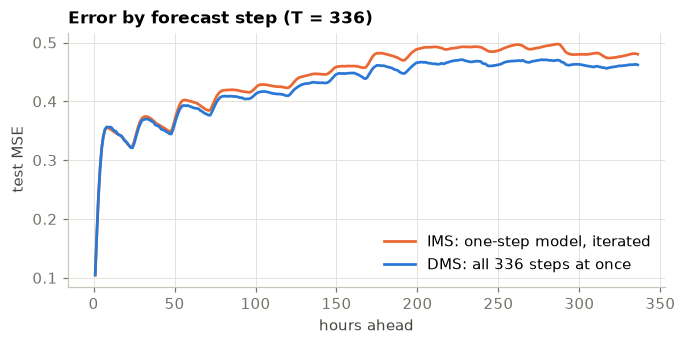

In [8]:
torch.manual_seed(0)
one_step = fit(Linear(L, 1, norm=True), L, 1)


@torch.no_grad()
def iterate(model, x, steps):
    window, out = x.clone(), []
    for _ in range(steps):
        nxt = model(window)
        out.append(nxt)
        window = torch.cat([window[:, 1:], nxt], dim=1)
    return torch.cat(out, dim=1)


rows, per_step = [], {}
for T_ in [96, 336, 720]:
    if T_ == T:
        dms_model = baselines["NLinear"]
    else:
        torch.manual_seed(0)
        dms_model = fit(Linear(L, T_, norm=True), L, T_)
    x_, y_ = windows(L, T_, "test")
    with torch.no_grad():
        ims, dms = iterate(one_step, x_, T_), dms_model(x_)
    per_step[T_] = (((ims - y_) ** 2).mean(0).numpy(), ((dms - y_) ** 2).mean(0).numpy())
    rows.append({"horizon T": T_, "IMS: one-step NLinear, iterated": per_step[T_][0].mean(), "DMS: NLinear": per_step[T_][1].mean()})
display(pd.DataFrame(rows).set_index("horizon T"))

fig, ax = plt.subplots(figsize=(7, 3))
h = np.arange(1, 337)
ax.plot(h, per_step[336][0], label="IMS: one-step model, iterated", color=ORANGE)
ax.plot(h, per_step[336][1], label="DMS: all 336 steps at once", color=BLUE)
ax.set_xlabel("hours ahead")
ax.set_ylabel("test MSE")
ax.set_title("Error by forecast step (T = 336)", loc="left")
ax.legend()
plt.show()

For a **linear** model the IMS penalty is small: a tie at 96 hours, 1–4% at 336–720 hours. Iterating a linear map is itself a linear
map of the input, so nothing compounds through a nonlinearity. The error accumulation the paper warns about bites harder in the deep
autoregressive baselines the Transformer papers compared with. Every model below is DMS.

## 4. From LTSF-Linear to an autoencoder

### 4.1 Is the linear map low-rank?

NLinear's weight matrix $W$ has $T \times L = 96 \times 336 = 32{,}256$ entries. Each row says how the 336 past hours are weighted
to predict one future hour. How many *independent* patterns does it really use? The singular value decomposition
$W = U \Sigma V^\top$ answers that. If only a few singular values are large, $W$ is close to a rank-$k$ matrix.

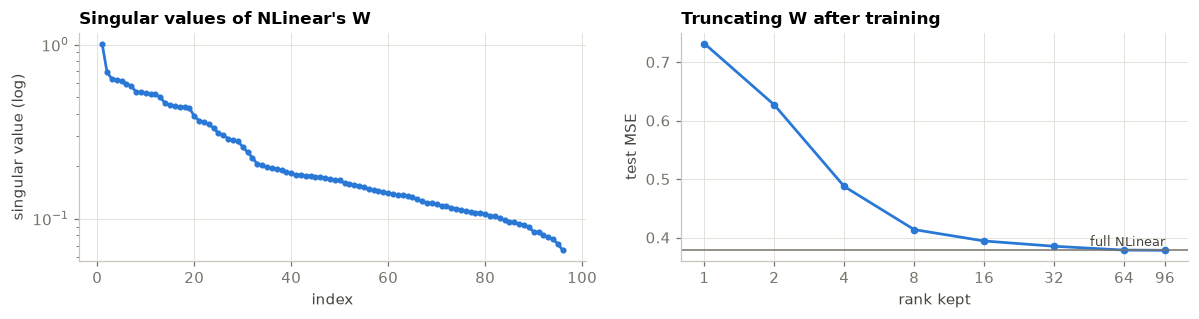

energy captured by the top 1/2/4/8/16 directions: 11.8% 17.4% 26.6% 42.2% 64.7%


In [9]:
W = baselines["NLinear"].lin.weight.detach().clone()
U_, S_, Vt_ = torch.linalg.svd(W, full_matrices=False)
energy = (S_ ** 2).cumsum(0) / (S_ ** 2).sum()

ranks = [1, 2, 4, 8, 16, 32, 64, 96]
svd_mse = []
for r in ranks:
    trunc = Linear(L, T, norm=True)
    trunc.lin.weight.data = U_[:, :r] @ torch.diag(S_[:r]) @ Vt_[:r]
    trunc.lin.bias.data = baselines["NLinear"].lin.bias.detach().clone()
    svd_mse.append(evaluate(trunc, L, T)[0])

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].semilogy(np.arange(1, len(S_) + 1), S_.numpy(), marker="o", ms=3, color=BLUE)
axes[0].set_xlabel("index")
axes[0].set_ylabel("singular value (log)")
axes[0].set_title("Singular values of NLinear's W", loc="left")
axes[1].plot(ranks, svd_mse, marker="o", ms=4, color=BLUE)
axes[1].axhline(evaluate(baselines["NLinear"], L, T)[0], color=MUTED, lw=1)
axes[1].text(96, svd_mse[-1] + 0.002, "full NLinear", ha="right", va="bottom", fontsize=8.5, color=INK2)
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(ranks, [str(r) for r in ranks])
axes[1].set_xlabel("rank kept")
axes[1].set_ylabel("test MSE")
axes[1].set_title("Truncating W after training", loc="left")
plt.tight_layout()
plt.show()
print("energy captured by the top 1/2/4/8/16 directions:", " ".join(f"{energy[r - 1]:.1%}" for r in [1, 2, 4, 8, 16]))

The spectrum decays **slowly**. The top 16 directions hold only about two thirds of $W$'s energy, and cutting $W$ down after training
costs accuracy until rank 32–64. So NLinear's $W$, as trained, is *not* low-rank. Keep that in mind for the next experiment.

### 4.2 The forecaster as an autoencoder

A rank-$k$ matrix factors as $W = D\,E$ with $E \in \mathbb{R}^{k \times L}$ and $D \in \mathbb{R}^{T \times k}$. That is exactly a linear
autoencoder with a $k$-number bottleneck. The only change is that its decoder rebuilds the **future** instead of the past:

$$
\underbrace{z = E\,(x - x_L) + b_E}_{\text{encoder: } L \to k}, \qquad
\underbrace{\hat y = D\,z + b_D + x_L}_{\text{decoder: } k \to T}.
$$

Some call this a *predictive* autoencoder. Instead of truncating a trained $W$, we train $E$ and $D$ end to end. The bottleneck is then
a constraint the model is trained under, not a compression applied afterwards. Options for the paper's other lessons are built in:
NLinear normalization (`norm`), DLinear decomposition (`decomp`, one encoder/decoder pair per component), a nonlinear encoder (`hidden`),
and a reconstruction head that also rebuilds the past (`recon`, used in section 5).

k=  1  test MSE 0.6256  parameters    529


k=  2  test MSE 0.5164  parameters    962


k=  4  test MSE 0.4127  parameters  1,828


k=  8  test MSE 0.3765  parameters  3,560


k= 16  test MSE 0.3751  parameters  7,024


k= 32  test MSE 0.3746  parameters 13,952


k= 64  test MSE 0.3748  parameters 27,808
NLinear  test MSE 0.3782  parameters 32,352


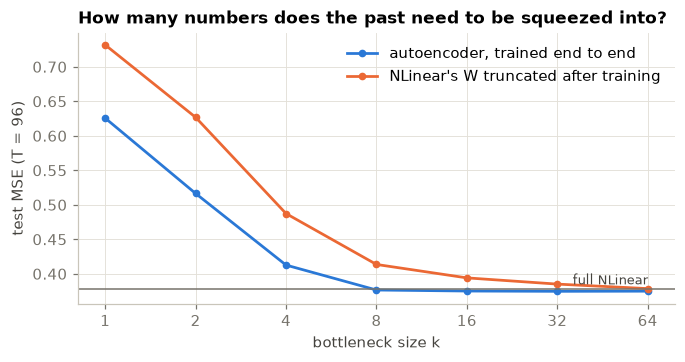

In [10]:
class BottleneckAE(nn.Module):
    """Forecasting autoencoder: past window -> k numbers -> future window (and optionally back to the past)."""

    def __init__(self, L, T, k, norm=True, decomp=False, hidden=0, recon=False):
        super().__init__()
        self.norm, self.decomp = norm, decomp
        branches = 2 if decomp else 1

        def encoder():
            if hidden:
                return nn.Sequential(nn.Linear(L, hidden), nn.GELU(), nn.Linear(hidden, k))
            return nn.Linear(L, k)

        self.encoders = nn.ModuleList([encoder() for _ in range(branches)])
        self.decoders = nn.ModuleList([nn.Linear(k, T) for _ in range(branches)])
        self.recon_heads = nn.ModuleList([nn.Linear(k, L) for _ in range(branches)]) if recon else None

    def _parts(self, x):
        last = x[:, -1:] if self.norm else torch.zeros_like(x[:, -1:])
        xn = x - last
        if self.decomp:
            trend = moving_avg(xn)
            return last, [xn - trend, trend]
        return last, [xn]

    def encode(self, x):
        last, parts = self._parts(x)
        return last, [enc(p) for enc, p in zip(self.encoders, parts)]

    def forward(self, x):
        last, zs = self.encode(x)
        return sum(dec(z) for dec, z in zip(self.decoders, zs)) + last

    def reconstruct(self, x):
        last, zs = self.encode(x)
        return sum(rec(z) for rec, z in zip(self.recon_heads, zs)) + last


ks = [1, 2, 4, 8, 16, 32, 64]
ae_by_k, ae_mse = {}, []
for k in ks:
    torch.manual_seed(0)
    ae_by_k[k] = fit(BottleneckAE(L, T, k), L, T)
    ae_mse.append(evaluate(ae_by_k[k], L, T)[0])
    print(f"k={k:3d}  test MSE {ae_mse[-1]:.4f}  parameters {n_params(ae_by_k[k]):6,d}")
nlinear_mse = evaluate(baselines["NLinear"], L, T)[0]
print(f"NLinear  test MSE {nlinear_mse:.4f}  parameters {n_params(baselines['NLinear']):6,d}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(ks, ae_mse, marker="o", ms=4, label="autoencoder, trained end to end", color=BLUE)
ax.plot(ranks[:-1], svd_mse[:-1], marker="o", ms=4, label="NLinear's W truncated after training", color=ORANGE)
ax.axhline(nlinear_mse, color=MUTED, lw=1)
ax.text(64, nlinear_mse + 0.002, "full NLinear", ha="right", va="bottom", fontsize=8.5, color=INK2)
ax.set_xscale("log", base=2)
ax.set_xticks(ks, [str(k) for k in ks])
ax.set_xlabel("bottleneck size k")
ax.set_ylabel("test MSE (T = 96)")
ax.set_title("How many numbers does the past need to be squeezed into?", loc="left")
ax.legend()
plt.show()

Trained end to end, the bottleneck tells a different story from truncation. With $k = 8$ the autoencoder already matches NLinear
(0.377 vs 0.378); $k = 16$ gives 0.375 with 7,024 parameters instead of 32,352. These differences are within seed-to-seed noise.
Truncation needed rank 32–64 for the same error.

The difference is *where* the constraint acts. A model trained under the bottleneck spends its few directions on what predicts the
future. NLinear spends its spare rank on fine detail that fits the training months but does not help on the test months. This is
the paper's remark that "using too many parameters will even cause overfitting", made concrete: the **useful** part of the linear
forecaster is low-rank, even though the trained matrix is not.

### 4.3 Looking inside: a learned basis for the future

With the linear AE, the forecast is literally a weighted sum of $k$ **basis curves**, the columns $d_j$ of the decoder:

$$ \hat y = x_L + b_D + \sum_{j=1}^{k} z_j\, d_j, \qquad z_j = \langle e_j,\, x - x_L \rangle + b_{E,j}. $$

Each code $z_j$ is a *filter response*: the dot product of the (normalized) past with an encoder row $e_j$. Here are both sets of curves
for $k = 8$. Each is scaled to unit maximum, since only their shapes matter here.

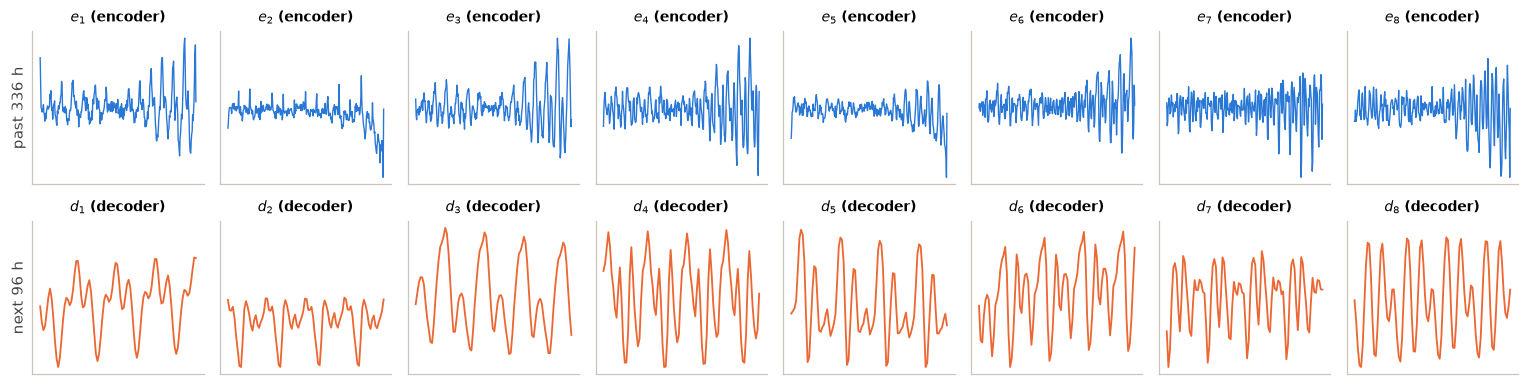

In [11]:
k_show = 8
ae8 = ae_by_k[k_show]
E8 = ae8.encoders[0].weight.detach().numpy()          # (k, L)
D8 = ae8.decoders[0].weight.detach().numpy()          # (T, k)
fig, axes = plt.subplots(2, k_show, figsize=(14, 3.6), sharey="row")
for j in range(k_show):
    axes[0, j].plot(np.arange(-L, 0), E8[j] / np.abs(E8[j]).max(), color=BLUE, lw=0.9)
    axes[1, j].plot(np.arange(1, T + 1), D8[:, j] / np.abs(D8[:, j]).max(), color=ORANGE, lw=1.2)
    axes[0, j].set_title(f"$e_{{{j + 1}}}$ (encoder)", fontsize=9)
    axes[1, j].set_title(f"$d_{{{j + 1}}}$ (decoder)", fontsize=9)
    for a in axes[:, j]:
        a.set_xticks([])
        a.set_yticks([])
axes[0, 0].set_ylabel("past 336 h")
axes[1, 0].set_ylabel("next 96 h")
plt.tight_layout()
plt.show()

The decoder curves $d_j$ are smooth daily patterns: peaks every 24 hours with different phases and shapes, like a Fourier basis tuned to
this data. The encoder rows $e_j$ are noisier, and their weight concentrates on the most recent days of the window. The forecast for the
next 96 hours is a mix of eight daily templates. The encoder's job is to read off how much of each template the recent past contains.

The product $D\,E$ is a $T \times L$ matrix like NLinear's $W$, so we can put them side by side. This is the same kind of picture as the
paper's Fig. 7, which shows DLinear's weights:

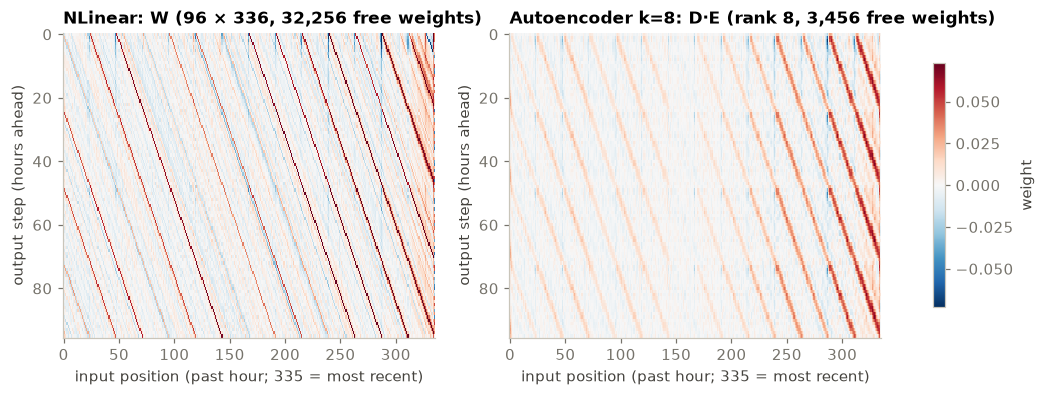

In [12]:
W_ae = (ae8.decoders[0].weight @ ae8.encoders[0].weight).detach().numpy()
W_nl = W.numpy()
lim = np.quantile(np.abs(np.concatenate([W_ae.ravel(), W_nl.ravel()])), 0.995)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, M_, title in [(axes[0], W_nl, "NLinear: W (96 × 336, 32,256 free weights)"),
                      (axes[1], W_ae, "Autoencoder k=8: D·E (rank 8, 3,456 free weights)")]:
    im = ax.imshow(M_, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto", interpolation="nearest")
    ax.set_xlabel("input position (past hour; 335 = most recent)")
    ax.set_ylabel("output step (hours ahead)")
    ax.set_title(title, loc="left")
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="weight")
plt.show()

Both show the signature of the paper's Fig. 7: diagonal stripes 24 hours apart. To predict hour $t + h$, look at the same hour on
previous days. NLinear's stripes run back through the whole 336-hour window and carry fine-grained noise. The rank-8 product keeps the
stripes, smooths them, and concentrates on the last four to five days, with 3,456 free weights instead of 32,256 and the same test error.

## 5. Other ways to use an autoencoder

The predictive AE above is one way to bring an autoencoder into forecasting. Three other classic recipes, all at $T = 96$:

* **Two-stage (representation learning).** First train an ordinary AE that reconstructs the past window (unsupervised). Then freeze the
  encoder and fit only a linear forecasting head on its codes. With linear layers, stage 1 recovers the principal subspace of the windows
  (PCA), so this is *principal component regression*.
* **Multi-task (reconstruct + forecast).** One shared code must both rebuild the past and predict the future:
  $\mathcal{L} = \mathrm{MSE}(\hat y, y) + \lambda\,\mathrm{MSE}(\hat x, x)$. N-BEATS' *backcast* uses a related idea.
* **Nonlinear encoder.** An MLP (336 → 256 → k, GELU) instead of a linear map. This tests the paper's warning that extra capacity
  tends to overfit on these benchmarks.

Alongside, the preprocessing ablations: without NLinear normalization, and with DLinear decomposition.

In [13]:
def recon_loss(model, x, y):
    return F.mse_loss(model.reconstruct(x), x)


def multitask_loss(lam):
    return lambda model, x, y: F.mse_loss(model(x), y) + lam * F.mse_loss(model.reconstruct(x), x)


def two_stage(k):
    model = BottleneckAE(L, T, k, recon=True)
    fit(model, L, T, loss_fn=recon_loss)                    # stage 1: unsupervised, reconstruct the past
    for p in list(model.encoders.parameters()) + list(model.recon_heads.parameters()):
        p.requires_grad_(False)                             # stage 2: freeze the encoder, fit the forecast head
    return fit(model, L, T)


variants = {
    "AE k=16 (predictive, NLinear norm)": lambda: fit(BottleneckAE(L, T, 16), L, T),
    "AE k=16 without normalization": lambda: fit(BottleneckAE(L, T, 16, norm=False), L, T),
    "AE k=16 + DLinear decomposition": lambda: fit(BottleneckAE(L, T, 16, decomp=True), L, T),
    "two-stage: AE on the past, then head": lambda: two_stage(16),
    "multi-task, λ = 0.1": lambda: fit(BottleneckAE(L, T, 16, recon=True), L, T, loss_fn=multitask_loss(0.1)),
    "multi-task, λ = 1": lambda: fit(BottleneckAE(L, T, 16, recon=True), L, T, loss_fn=multitask_loss(1.0)),
    "nonlinear encoder (MLP 256)": lambda: fit(BottleneckAE(L, T, 16, hidden=256), L, T),
}
rows = [{"model": "NLinear (reference)", "MSE": nlinear_mse, "MAE": evaluate(baselines["NLinear"], L, T)[1],
         "parameters": n_params(baselines["NLinear"])}]
for name, make in variants.items():
    torch.manual_seed(0)
    m = make()
    mse, mae = evaluate(m, L, T)
    rows.append({"model": name, "MSE": mse, "MAE": mae, "parameters": sum(p.numel() for p in m.parameters())})
pd.DataFrame(rows).set_index("model")

,MSE,MAE,parameters
model,,,
NLinear (reference),0.378,0.397,32352
"AE k=16 (predictive, NLinear norm)",0.375,0.398,7024
AE k=16 without normalization,0.370,0.395,7024
AE k=16 + DLinear decomposition,0.372,0.395,14048
"two-stage: AE on the past, then head",0.405,0.423,12736
"multi-task, λ = 0.1",0.374,0.398,12736
"multi-task, λ = 1",0.381,0.403,12736
nonlinear encoder (MLP 256),0.404,0.420,92016


What the table says ($T = 96$, one seed, so differences below about 0.005 are noise):

* **Predictive AE ≈ NLinear**, with 4.6× fewer parameters. Dropping the normalization or adding DLinear's decomposition changes little at
  this horizon; normalization matters at long horizons (section 6).
* **Two-stage is clearly worse** (0.405). An AE trained only to rebuild the past keeps what varies most *in the past*, which is not the
  same as what predicts the future. The supervision has to reach the bottleneck.
* **Multi-task** is harmless with a small weight (λ = 0.1) and slightly worse with λ = 1: rebuilding the past spends capacity on a task
  nobody scores.
* **The nonlinear encoder overfits** (0.404 with 92 K parameters), the same experience the paper reports for more complex models on these
  benchmarks.

## 6. Benchmark on all four horizons

The full ETTh1 comparison with our two main autoencoders ($k = 16$, with NLinear normalization, without and with decomposition), next
to our reproductions of the baselines and the paper's reported numbers (Transformers from the paper's Table 2, which in turn come from
FEDformer's paper). Expect ±0.01 of seed-to-seed noise on our numbers. Lower is better.

In [14]:
bench = {
    "Repeat": lambda T: Repeat(L, T), "Linear": lambda T: Linear(L, T), "NLinear": lambda T: Linear(L, T, norm=True),
    "DLinear": lambda T: DLinear(L, T), "AE k=16": lambda T: BottleneckAE(L, T, 16),
    "AE k=16 + decomp": lambda T: BottleneckAE(L, T, 16, decomp=True),
}
results, params = {}, {}
for T_ in [96, 192, 336, 720]:
    for name, make in bench.items():
        torch.manual_seed(0)
        m = fit(make(T_), L, T_)
        results[(name, T_)] = evaluate(m, L, T_)
        params[(name, T_)] = n_params(m)

table = pd.DataFrame({
    T_: {**{f"{n} (ours)": results[(n, T_)][0] for n in bench},
         **{f"{n} (paper)": PAPER[T_][n][0] for n in ["NLinear", "DLinear", "FEDformer", "Autoformer", "Informer"]}}
    for T_ in [96, 192, 336, 720]
})
table.index.name = "test MSE, ETTh1"
table.columns.name = "horizon T"
table

horizon T,96,192,336,720
"test MSE, ETTh1",,,,
Repeat (ours),1.294,1.325,1.330,1.335
Linear (ours),0.375,0.419,0.507,0.528
NLinear (ours),0.378,0.408,0.428,0.435
DLinear (ours),0.377,0.408,0.535,0.529
AE k=16 (ours),0.375,0.412,0.426,0.432
AE k=16 + decomp (ours),0.372,0.414,0.426,0.432
NLinear (paper),0.374,0.408,0.429,0.440
DLinear (paper),0.375,0.405,0.439,0.472
FEDformer (paper),0.376,0.420,0.459,0.506


In [15]:
ptable = pd.DataFrame({T_: {n: params[(n, T_)] for n in bench} for T_ in [96, 192, 336, 720]})
ptable.index.name = "trainable parameters"
ptable.columns.name = "horizon T"
ptable

horizon T,96,192,336,720
trainable parameters,,,,
Repeat,0,0,0,0
Linear,32352,64704,113232,242640
NLinear,32352,64704,113232,242640
DLinear,64704,129408,226464,485280
AE k=16,7024,8656,11104,17632
AE k=16 + decomp,14048,17312,22208,35264


* Our NLinear matches the paper within 0.005 at every horizon. Linear and DLinear **without** normalization degrade at 336–720 hours (ours
  0.507–0.535 vs NLinear's 0.428–0.435): that is the distribution shift from section 2. The paper's DLinear did better at those horizons
  (0.439 / 0.472); unnormalized linear models are sensitive to the training run.
* **The autoencoder ties NLinear at every horizon** (0.375 / 0.412 / 0.426 / 0.432). It ties the best Transformer reported for ETTh1 at
  96 hours (FEDformer, 0.376) and beats it from 192 hours on (0.420 / 0.459 / 0.506). As in the paper, the Transformers use $L = 96$, their best
  setting, and the linear models $L = 336$.
* Its size grows with $k(L + T)$ instead of $L \cdot T$: 17.6 K parameters at $T = 720$ instead of 242.6 K, 14× fewer.

## 7. The paper's diagnostics, applied to the autoencoder

### 7.1 Does a longer look-back help?

The paper's Fig. 4 shows Transformers getting *worse* or flat as the look-back window $L$ grows, while linear models improve. A model
that really extracts temporal information should improve with more history. Repeat the experiment for the AE at $T = 720$:

L=  48  NLinear 0.5007  AE 0.5002


L=  96  NLinear 0.4697  AE 0.4704


L= 192  NLinear 0.4452  AE 0.4431


L= 336  NLinear 0.4349  AE 0.4316


L= 504  NLinear 0.4403  AE 0.4363


L= 720  NLinear 0.4573  AE 0.4598


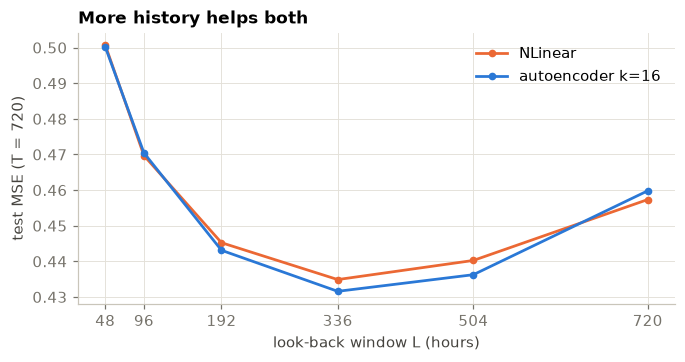

In [16]:
looks = [48, 96, 192, 336, 504, 720]
lb = {"NLinear": [], "AE k=16": []}
for L_ in looks:
    for name, make in [("NLinear", lambda: Linear(L_, 720, norm=True)), ("AE k=16", lambda: BottleneckAE(L_, 720, 16))]:
        torch.manual_seed(0)
        lb[name].append(evaluate(fit(make(), L_, 720), L_, 720)[0])
    print(f"L={L_:4d}  NLinear {lb['NLinear'][-1]:.4f}  AE {lb['AE k=16'][-1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(looks, lb["NLinear"], marker="o", ms=4, label="NLinear", color=ORANGE)
ax.plot(looks, lb["AE k=16"], marker="o", ms=4, label="autoencoder k=16", color=BLUE)
ax.set_xticks(looks)
ax.set_xlabel("look-back window L (hours)")
ax.set_ylabel("test MSE (T = 720)")
ax.set_title("More history helps both", loc="left")
ax.legend()
plt.show()

Both improve as the window grows from 48 to 336 hours (0.50 → 0.43), as the paper found for its linear models and unlike the
Transformers. Beyond 336 hours both get slightly worse again (about 0.44 at 504, 0.46 at 720). ETTh1 has only 12 months of training data,
and longer windows mean fewer training windows and more weights per output. The AE tracks NLinear at every $L$, so the bottleneck costs
nothing in the paper's own test of temporal modelling.

### 7.2 Does it use the order of the input?

Table 5 of the paper scrambles the input window at test time. In **Shuf.** the whole window is randomly permuted; in **Half-Ex.** its first and
second halves are swapped. A model that uses temporal order must get worse. Informer barely noticed (+2% on ETTh1), Linear lost 81% under Shuf.

In [17]:
def shuffle(x, seed=0):
    g = torch.Generator().manual_seed(seed)
    return x[:, torch.randperm(x.shape[1], generator=g)]


def half_exchange(x):
    h = x.shape[1] // 2
    return torch.cat([x[:, h:], x[:, :h]], dim=1)


ae16 = ae_by_k[16]
rows = []
for name, model in [("Linear", baselines["Linear"]), ("NLinear", baselines["NLinear"]), ("AE k=16", ae16)]:
    ori = evaluate(model, L, T)[0]
    shu = evaluate(model, L, T, transform=shuffle)[0]
    hal = evaluate(model, L, T, transform=half_exchange)[0]
    rows.append({"model": name, "Ori.": ori, "Shuf.": shu, "Half-Ex.": hal,
                 "drop Shuf.": f"{shu / ori - 1:+.0%}", "drop Half-Ex.": f"{hal / ori - 1:+.0%}"})
rows.append({"model": "Informer (paper, T=96)", "Ori.": .974, "Shuf.": .971, "Half-Ex.": .971, "drop Shuf.": "+2% (avg.)", "drop Half-Ex.": "+0% (avg.)"})
pd.DataFrame(rows).set_index("model")

,Ori.,Shuf.,Half-Ex.,drop Shuf.,drop Half-Ex.
model,,,,,
Linear,0.375,0.820,0.497,+118%,+32%
NLinear,0.378,0.830,0.504,+120%,+33%
AE k=16,0.375,0.815,0.496,+117%,+32%
"Informer (paper, T=96)",0.974,0.971,0.971,+2% (avg.),+0% (avg.)


Scrambling the window more than doubles the error of all three linear models, the AE included (+117% under Shuf.). Swapping the halves
costs about a third. The AE reads the order of its input as much as Linear does: that is what Table 5 asks of a temporal model, and what
Informer did not do. Our drops are larger than the paper's figures for Linear (81% and 5%). We apply one fixed permutation at test time
only, and report $T = 96$ rather than an average over four horizons.

### 7.3 Efficiency

Per variable and per window, Linear/NLinear does $L \cdot T$ multiply–adds and DLinear $2LT$. The AE does $k(L + T)$. At $L = 336$, $T = 720$,
that is 242 K for NLinear vs 17 K for the AE with $k = 16$, a 14× saving, on top of a model that was already about 100× cheaper than
the Transformers (paper, Table 8).

In [18]:
for T_ in [96, 720]:
    print(f"T={T_:3d}:  NLinear {L * T_:>8,d} MACs   DLinear {2 * L * T_:>8,d}   AE k=16 {16 * (L + T_):>7,d}   "
          f"ratio NLinear/AE = {L * T_ / (16 * (L + T_)):.1f}×")

T= 96:  NLinear   32,256 MACs   DLinear   64,512   AE k=16   6,912   ratio NLinear/AE = 4.7×
T=720:  NLinear  241,920 MACs   DLinear  483,840   AE k=16  16,896   ratio NLinear/AE = 14.3×


## 8. A conditional VAE for probabilistic forecasts

A point forecast says nothing about how sure the model is. The variational side of autoencoders adds that. A **conditional VAE**
(Sohn et al., 2015) models $p(y \mid x)$ through a latent variable:

$$ p(y \mid x) = \int p_\theta(y \mid x, z)\, p_\psi(z \mid x)\, dz . $$

Our design keeps the paper's lessons. The mean path is the linear AE from section 4, and the latent variable only adds structured
**deviations** around it:

$$ \hat y(z) = \underbrace{x_L + D\,E\,(x - x_L)}_{\text{linear AE (deterministic)}} + \underbrace{U z}_{\text{learned deviation modes}}, \qquad
y \mid x, z \sim \mathcal{N}\big(\hat y(z), \operatorname{diag}\sigma_t^2\big). $$

* **Prior** $p_\psi(z \mid x) = \mathcal{N}(\mu_p(x), \sigma_p^2(x))$: a small network reads the past and says *how uncertain this window is*.
* **Posterior** $q_\phi(z \mid x, y)$: during training it also sees the actual future (through the base model's residual) and encodes
  *which deviation actually happened*.
* **Loss**: the negative conditional ELBO, $\; -\mathbb{E}_q[\log p_\theta(y\mid x, z)] + \beta\,\mathrm{KL}(q_\phi(z\mid x,y)\,\|\,p_\psi(z\mid x))$,
  with $\beta = 1$ and a learned per-step noise level $\sigma_t$.
* **Forecasting**: draw $z$ from the prior, decode, add noise $\sigma_t \varepsilon$. Repeating this gives a distribution of futures.

Because $U z$ adds one deviation curve to *every* step at once, the samples come out as coherent trajectories (for example
"the whole day runs hotter"), not independent noise at each hour.

In [19]:
class ForecastCVAE(nn.Module):
    def __init__(self, L, T, k=16, kz=8, hidden=64):
        super().__init__()
        self.E, self.D = nn.Linear(L, k), nn.Linear(k, T)                  # deterministic linear AE path
        self.h = nn.Linear(L, hidden)                                       # shared summary of the past
        self.prior = nn.Linear(hidden, 2 * kz)                              # p(z | x)
        self.posterior = nn.Sequential(nn.Linear(hidden + T, hidden), nn.Tanh(), nn.Linear(hidden, 2 * kz))   # q(z | x, y)
        self.U = nn.Linear(kz, T, bias=False)                               # deviation modes
        self.log_sigma = nn.Parameter(torch.full((T,), -0.5))               # per-step observation noise

    def _base(self, x):
        last = x[:, -1:]
        xn = x - last
        return last, self.D(self.E(xn)) + last, torch.tanh(self.h(xn))

    def elbo_terms(self, x, y):
        last, base, h = self._base(x)
        mu_p, logvar_p = self.prior(h).chunk(2, -1)
        mu_q, logvar_q = self.posterior(torch.cat([h, y - base], -1)).chunk(2, -1)
        z = mu_q + torch.randn_like(mu_q) * torch.exp(0.5 * logvar_q)
        mean = base + self.U(z)
        var = torch.exp(2 * self.log_sigma)
        nll = (0.5 * (y - mean) ** 2 / var + self.log_sigma + 0.5 * math.log(2 * math.pi)).sum(-1)
        kl = 0.5 * (logvar_p - logvar_q + (logvar_q.exp() + (mu_q - mu_p) ** 2) / logvar_p.exp() - 1).sum(-1)
        return nll, kl

    def forward(self, x):                      # point forecast: the decoded prior mean
        _, base, h = self._base(x)
        mu_p, _ = self.prior(h).chunk(2, -1)
        return base + self.U(mu_p)

    @torch.no_grad()
    def sample(self, x, n, noise=True):
        _, base, h = self._base(x)
        mu_p, logvar_p = self.prior(h).chunk(2, -1)
        z = mu_p + torch.randn(n, *mu_p.shape) * torch.exp(0.5 * logvar_p)
        out = base + self.U(z)
        return out + torch.randn(n, *base.shape) * self.log_sigma.exp() if noise else out


def cvae_loss(beta=1.0):
    def loss(model, x, y):
        if not model.training:                 # validation: the full objective, so early stopping tracks the ELBO
            torch.manual_seed(1)
        nll, kl = model.elbo_terms(x, y)
        return (nll + beta * kl).mean() / y.shape[1]
    return loss


torch.manual_seed(0)
t0 = time.time()
cvae = fit(ForecastCVAE(L, T), L, T, loss_fn=cvae_loss(), lr=0.003, bs=64)
print(f"trained in {time.time() - t0:.0f}s · point-forecast test MSE {evaluate(cvae, L, T)[0]:.4f}")

trained in 5s · point-forecast test MSE 0.3663


**Scoring a distribution.** Three standard checks on all test windows, with 100 sampled futures each:

* **coverage** of the central 80% interval: the share of true values inside the 10th–90th percentile band. It should be close to 80%;
* **width** of that band: narrower is better, *at the same coverage*;
* **CRPS** (continuous ranked probability score), $\mathbb{E}|Y - y| - \tfrac12\,\mathbb{E}|Y - Y'|$ for $Y, Y'$ drawn from the forecast and $y$ the truth.
  It rewards being both calibrated and sharp. It equals the MAE for a point forecast. Lower is better.

The baseline is the deterministic AE ($k = 16$) plus Gaussian noise whose per-step standard deviation is set from validation residuals.
This is the usual "error bars from the residuals" approach: same width for every window, independent across steps.

In [20]:
@torch.no_grad()
def prob_scores(sampler, x, y, n=100, chunk=2500, seed=0):
    torch.manual_seed(seed)
    inside = width = crps = 0.0
    for i in range(0, len(x), chunk):
        s = sampler(x[i:i + chunk], n)                                  # (n, batch, T)
        yy = y[i:i + chunk]
        lo, hi = s.quantile(0.1, 0), s.quantile(0.9, 0)
        inside += ((yy >= lo) & (yy <= hi)).float().sum().item()
        width += (hi - lo).sum().item()
        ss, _ = s.sort(0)
        w = (2 * torch.arange(1, n + 1) - n - 1).float().view(-1, 1, 1)
        crps += ((s - yy[None]).abs().mean(0) - (w * ss).sum(0) / n ** 2).sum().item()
    total = y.numel()
    return inside / total, width / total, crps / total


xv, yv = windows(L, T, "val")
with torch.no_grad():
    resid_sd = (ae16(xv) - yv).std(0)
baseline_sampler = lambda x, n: ae16(x)[None] + torch.randn(n, len(x), T) * resid_sd
cvae.eval()
rows = []
for name, sampler, point in [("AE k=16 + residual Gaussian", baseline_sampler, ae16), ("conditional VAE", cvae.sample, cvae)]:
    cov, wid, crps = prob_scores(sampler, x_te, y_te)
    rows.append({"model": name, "MSE (point)": evaluate(point, L, T)[0], "80% coverage": f"{cov:.1%}",
                 "80% width": wid, "CRPS": crps})
pd.DataFrame(rows).set_index("model")

,MSE (point),80% coverage,80% width,CRPS
model,,,,
AE k=16 + residual Gaussian,0.375,91.1%,2.022,0.336
conditional VAE,0.366,84.6%,1.342,0.301


The CVAE does better on every score:

* its **point forecast** improves slightly (0.366 vs 0.375): the prior mean adds a learned, window-dependent correction to the linear AE;
* its **80% band is a third narrower** (1.34 vs 2.02 standardized units) and still covers 85% of the truth;
* its **CRPS is 10% lower** (0.301 vs 0.336).

Both methods over-cover on the test months. The validation months are much harder to forecast (NLinear's validation MSE is about 0.66,
against 0.38 on test). Error bars sized on them are too wide for the test period. The residual baseline suffers most (91% coverage).
The CVAE's width depends on each window's input, not on one global residual level.

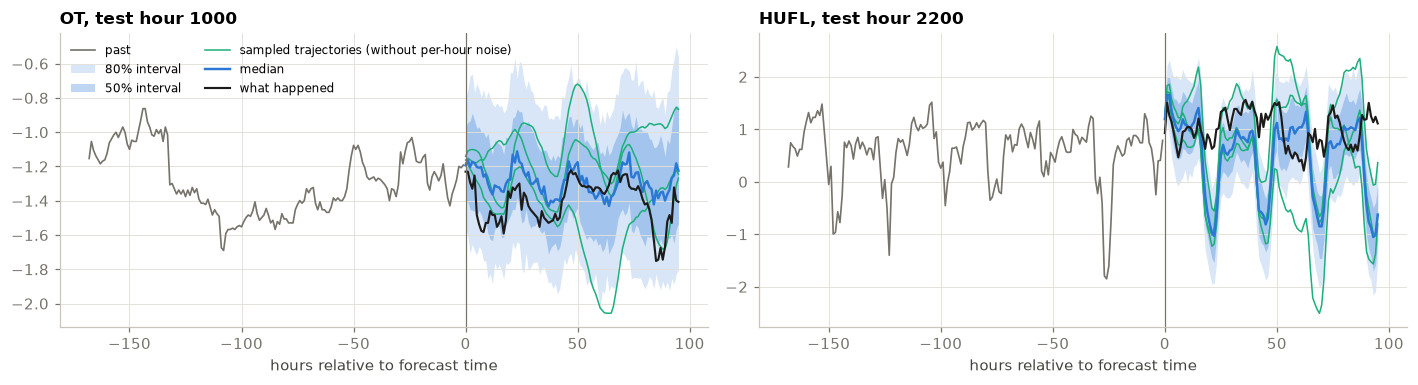

In [21]:
@torch.no_grad()
def fan_chart(ax, model, var, start, n=300, hist=168):
    """Forecast one test window of one variable: history, truth, median, 50% and 80% bands, three sampled trajectories."""
    a = BORDERS["test"][0] + start
    x = series[a - L:a, VARS.index(var)][None]
    y = series[a:a + T, VARS.index(var)]
    torch.manual_seed(0)
    s = model.sample(x, n)[:, 0]
    paths = model.sample(x, 3, noise=False)[:, 0]
    q = s.quantile(torch.tensor([0.1, 0.25, 0.5, 0.75, 0.9]), dim=0)
    th, tf = np.arange(-hist, 0), np.arange(0, T)
    ax.plot(th, x[0, -hist:], color=MUTED, lw=1.1, label="past")
    ax.fill_between(tf, q[0], q[4], color=BLUE, alpha=0.18, lw=0, label="80% interval")
    ax.fill_between(tf, q[1], q[3], color=BLUE, alpha=0.30, lw=0, label="50% interval")
    for i in range(3):
        ax.plot(tf, paths[i], color=AQUA, lw=1.0, label="sampled trajectories (without per-hour noise)" if i == 0 else None)
    ax.plot(tf, q[2], color=BLUE, lw=1.6, label="median")
    ax.plot(tf, y, color=INK, lw=1.4, label="what happened")
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_title(f"{var}, test hour {start}", loc="left")
    ax.set_xlabel("hours relative to forecast time")


fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=False)
fan_chart(axes[0], cvae, "OT", 1000)
fan_chart(axes[1], cvae, "HUFL", 2200)
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

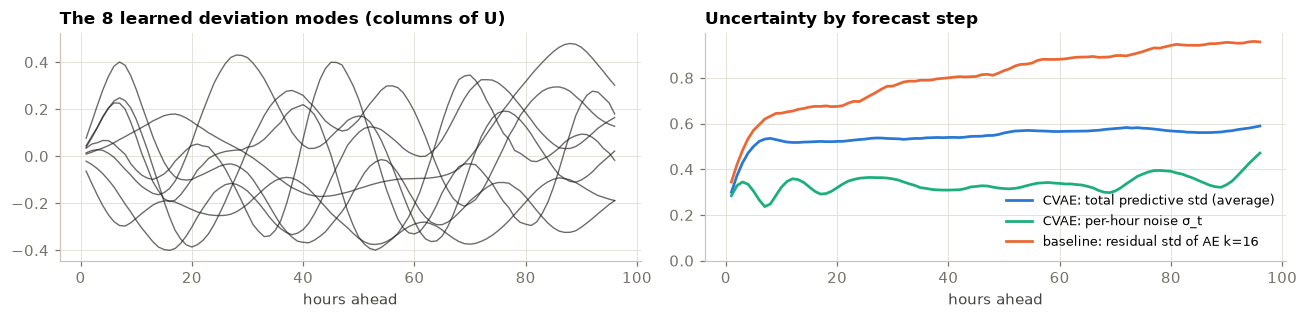

spread contributed by z, per window: 0.24 to 0.64 (5th to 95th percentile; median 0.37)


In [22]:
with torch.no_grad():
    _, _, h_te = cvae._base(x_te)
    prior_var = torch.exp(cvae.prior(h_te).chunk(2, -1)[1])                  # (windows, kz)
    fan_sd = (prior_var @ (cvae.U.weight.T ** 2)).sqrt().mean(1)              # spread added by z, per window
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
Uw = cvae.U.weight.detach().numpy()
order = np.argsort(-np.abs(Uw).max(0))
for j in order:
    axes[0].plot(np.arange(1, T + 1), Uw[:, j], color=INK, lw=0.9, alpha=0.65)
axes[0].set_title("The 8 learned deviation modes (columns of U)", loc="left")
axes[0].set_xlabel("hours ahead")
total_sd = ((prior_var @ (cvae.U.weight.T ** 2)).mean(0) + torch.exp(2 * cvae.log_sigma)).sqrt().detach()
axes[1].plot(np.arange(1, T + 1), total_sd, color=BLUE, label="CVAE: total predictive std (average)")
axes[1].plot(np.arange(1, T + 1), cvae.log_sigma.exp().detach(), color=AQUA, label="CVAE: per-hour noise σ_t")
axes[1].plot(np.arange(1, T + 1), resid_sd, color=ORANGE, label="baseline: residual std of AE k=16")
axes[1].set_title("Uncertainty by forecast step", loc="left")
axes[1].set_xlabel("hours ahead")
axes[1].set_ylim(0, None)
axes[1].legend(fontsize=8.5)
plt.tight_layout()
plt.show()
print(f"spread contributed by z, per window: {fan_sd.quantile(0.05):.2f} to {fan_sd.quantile(0.95):.2f} "
      f"(5th to 95th percentile; median {fan_sd.median():.2f})")

The bands widen where the series is hard to call, for example around HUFL's daily peaks. The sampled trajectories show what the latent
variable adds: each one is a whole coherent alternative future (a warmer day, an earlier dip), not 96 independent coin flips.
On the right, the per-hour noise $\sigma_t$ stays roughly flat. The CVAE's total spread rises over the first few hours and then
levels off around 0.55–0.6, while the residual baseline keeps growing to about 0.95. That gap is where the narrower bands come from.
Since the CVAE still covers more than 80%, the baseline was simply too wide. The spread added by $z$ also differs from window to
window, by a factor of almost 3 between the 5th and 95th percentile. A fixed residual band cannot do that.

## 9. Takeaways and related work

1. **LTSF-Linear is close to an autoencoder.** Its useful part factors into an encoder (past → $k$ numbers) and a decoder
   (numbers → future). Training it that way loses nothing: the same error as NLinear at all four horizons, with 5–14× fewer parameters.
2. **Keep the paper's lessons and the AE inherits LTSF-Linear's strengths.** That means DMS output, channel independence, last-value
   normalization, a linear (order-aware) encoder over the whole window, and few parameters. The result improves with more history (up to
   the data's limit) and is as sensitive to input order as Linear.
3. **The classic AE recipes don't transfer as they are.** Unsupervised pre-training (two-stage) and nonlinear encoders lose accuracy, and
   reconstruction as an auxiliary task doesn't help. What works is putting the bottleneck *between the past and the future*.
4. **The bottleneck buys interpretability.** The decoder learns a basis of daily templates and the encoder learns the filters that read off
   their weights. Sixteen curves are something you can inspect; a 32 K-entry matrix is not.
5. **The variational version buys uncertainty.** A conditional VAE on top of the linear AE gives sharper prediction intervals that are still
   conservative (CRPS −10%), and coherent sample trajectories.

### Where autoencoders show up in modern forecasters

* **N-BEATS** (Oreshkin et al., ICLR 2020) forecasts with stacks of MLP blocks. Each block outputs a *backcast* (a reconstruction of its input)
  and a forecast as weighted sums of basis functions, which is the decoder-basis picture of section 4.3.
* **PatchTST** (Nie et al., ICLR 2023), written partly in response to this paper, keeps a Transformer but adopts channel independence and
  patches. Its self-supervised version is pre-trained as a **masked autoencoder** that reconstructs hidden patches.
* **TiDE** (Das et al., TMLR 2023) is an MLP **encoder–decoder** for long-term forecasting with a linear residual path. It is close to the
  "nonlinear encoder" variant above, with covariates added.
* **RevIN** (Kim et al., ICLR 2022) generalizes NLinear's trick: normalize each input window, then de-normalize the output.
* **TimeVAE** (Desai et al., 2021) uses a VAE to *generate* realistic synthetic series. Its decoder also has explicit trend and seasonality blocks.
* **Anomaly detection** by reconstruction error (notebook 01, section 7.2) is a standard use of AEs on sensor data. The paper's conclusion asks
  the community to revisit Transformer-based solutions for that task too.

### References

* A. Zeng, M. Chen, L. Zhang, Q. Xu. *Are Transformers Effective for Time Series Forecasting?* AAAI 2023. [arXiv:2205.13504](https://arxiv.org/abs/2205.13504) · [code](https://github.com/cure-lab/LTSF-Linear)
* H. Zhou et al. *Informer: Beyond efficient transformer for long sequence time-series forecasting.* AAAI 2021 (ETT datasets).
* H. Wu, J. Xu, J. Wang, M. Long. *Autoformer: Decomposition transformers with auto-correlation for long-term series forecasting.* NeurIPS 2021.
* T. Zhou et al. *FEDformer: Frequency enhanced decomposed transformer for long-term series forecasting.* ICML 2022.
* K. Sohn, H. Lee, X. Yan. *Learning structured output representation using deep conditional generative models.* NeurIPS 2015.
* B. N. Oreshkin, D. Carpov, N. Chapados, Y. Bengio. *N-BEATS: Neural basis expansion analysis for interpretable time series forecasting.* ICLR 2020.
* Y. Nie, N. H. Nguyen, P. Sinthong, J. Kalagnanam. *A time series is worth 64 words: long-term forecasting with Transformers.* ICLR 2023.
* A. Das et al. *Long-term forecasting with TiDE: Time-series dense encoder.* TMLR 2023.
* T. Kim et al. *Reversible instance normalization for accurate time-series forecasting against distribution shift.* ICLR 2022.
* A. Desai, C. Freeman, Z. Wang, I. Beaver. *TimeVAE: A variational auto-encoder for multivariate time series generation.* arXiv:2111.08095, 2021.
* T. Gneiting, A. E. Raftery. *Strictly proper scoring rules, prediction, and estimation.* JASA 2007 (CRPS).